In [51]:
### 
### This script generates the parameters for extrusion simulations with WT 6h
import json
import numpy as np
import sympy as sym 
import tellurium as te
import pandas as pd
from pathlib import Path
from itertools import product

In [52]:
# Load configuration files
def load_config(filename):
    """Load configuration from JSON file"""
    with open(filename, 'r') as f:
        return json.load(f)

## Parameter inference

In [53]:
## Rates for extrusive network
rates_ext = sym.symbols("Kext_R_free_RN, Kext_RN_R, Kext_R_RN, Kext_R_RP, Kext_RP_R, Kext_RP_RPW, Kext_RPW_RP, Kext_RPW_R_free")
Kext_R_free_RN, Kext_RN_R, Kext_R_RN, Kext_R_RP, Kext_RP_R, Kext_RP_RPW, Kext_RPW_RP, Kext_RPW_R_free = rates_ext

paras_ext = sym.symbols("tau_N_ext, F_N_ext, N_N_ext, tau_W_ext, F_W_ext, N_W_ext, tau_P_ext, F_P_ext, N_P_ext, tau_R_ext, F_R_ext, N_R_ext")
tau_N_ext, F_N_ext, N_N_ext, tau_W_ext, F_W_ext, N_W_ext, tau_P_ext, F_P_ext, N_P_ext, tau_R_ext, F_R_ext, N_R_ext = paras_ext

## Equations for extrusive network
rhs_ext = [ Kext_RN_R - 1 / tau_N_ext,  # NIPBL unbinding kinetics
        Kext_R_free_RN * N_R_ext *(1-F_R_ext) + Kext_R_RN * (N_R_ext*F_R_ext - N_N_ext*F_N_ext - N_P_ext*F_P_ext) -  F_N_ext / tau_N_ext/ (1-F_N_ext), # NIPBL binding equilibrium
        Kext_RP_R * (N_P_ext * F_P_ext - N_W_ext * F_W_ext) + Kext_RPW_R_free * N_W_ext * F_W_ext  - N_P_ext * F_P_ext/tau_P_ext, # PDS5 unbinding kinetics
        Kext_R_RP * (N_R_ext * F_R_ext - N_N_ext * F_N_ext - N_P_ext * F_P_ext)  - F_P_ext / tau_P_ext /(1-F_P_ext), # PDS5 binding equilibrium,
        Kext_RPW_RP + Kext_RPW_R_free - 1 / tau_W_ext, # WAPL unbinding kinetics
        Kext_RP_RPW * (N_P_ext * F_P_ext - N_W_ext* F_W_ext)  - F_W_ext / tau_W_ext / (1-F_W_ext), # WAPL binding equilibrium
        Kext_RPW_R_free * N_W_ext * F_W_ext - F_R_ext * N_R_ext / tau_R_ext,  # RAD21 unbinding kinetics
        Kext_R_free_RN * N_N_ext * (1-F_N_ext) - F_R_ext / tau_R_ext / (1-F_R_ext) # RAD21 binding equilibrium, 
]

sol_rates_ext = sym.solve(rhs_ext, rates_ext)

In [54]:
## models for combined cohesive and extrusive networks
model_ext ='''
    # Define species and parameters

    # Extrusive network 
    R_free + N -> RN; Kext_R_free_RN*R_free*N 
    RN  -> R + N; Kext_RN_R*RN - Kext_R_RN*R*N
    R + P -> RP; Kext_R_RP*R*P - Kext_RP_R*RP
    RP + W -> RPW; Kext_RP_RPW*RP*W - Kext_RPW_RP*RPW 
    RPW -> R_free + P + W; Kext_RPW_R_free*RPW
    
    # Rates for extrusive network, 8 rates
    Kext_R_free_RN = {Kext_R_free_RN};
    Kext_RN_R = {Kext_RN_R};
    Kext_R_RN = {Kext_R_RN};
    Kext_R_RP = {Kext_R_RP};
    Kext_RP_R = {Kext_RP_R};
    Kext_RP_RPW = {Kext_RP_RPW};
    Kext_RPW_RP = {Kext_RPW_RP};
    Kext_RPW_R_free = {Kext_RPW_R_free};
    
    R_free = {R_free_init};
    RN = {RN_init};
    R = {R_init};
    RP = {RP_init};
    RPW = {RPW_init};
    
    N = {N_init};
    W = {W_init}; 
    P = {P_init};
    '''


In [55]:
def build_model(model, parameter_dict):
    string_params = {str(k): v for k, v in parameter_dict.items()}
    return model.format(**string_params)

def calculate_sister_RAD21_bound_time(K_RacPW_Rac_free, B_W_sister, B_R_sister):
    # K_RPW_R_free * N_W * F_W - F_R_sister*N_R/tau_R
    ### F_R is the fraction of bounded RAD21, T_W is the total number of bounded Wapl 
    return B_R_sister/(K_RacPW_Rac_free * B_W_sister)


In [56]:
def calculate_extrusive_parameters(config):
    """
    Calculate extrusive network parameters from configuration
    
    Args:
        config: Dictionary containing base parameters and modifiers
    
    Returns:
        List of extrusive parameter values
    """
    base = config['base_parameters']    
    return [
        base['tau_N'],
        base['F_N'],
        base['N_N'],
        base['tau_W'],
        base['F_W'],
        base['N_W'],
        base['tau_P'],
        base['F_P'],
        base['N_P'],
        base["tau_R"], 
        base["F_R"], 
        base['N_R'],
    ]

In [57]:
config = load_config('network_parameters_WT_G1_RPW.json')

In [58]:
# Calculate extrusive parameters
paras_values_ext = calculate_extrusive_parameters(config)
paras_dict_ext_local = dict(zip(paras_ext, paras_values_ext))

# Solve for extrusive rates
for rate_symbol, rate_expr in sol_rates_ext.items():
    rate = rate_expr.evalf(subs=paras_dict_ext_local)
    paras_dict_ext_local[rate_symbol] = rate

# Define symbolic initial conditions
R_free_init, RN_init, R_init, RP_init, RPW_init, N_init, W_init, P_init = sym.symbols(
        "R_free_init, RN_init, R_init, RP_init, RPW_init, N_init, W_init, P_init")
    

In [59]:
paras_dict_ext_local

{tau_N_ext: 72,
 F_N_ext: 0.4,
 N_N_ext: 111,
 tau_W_ext: 45.0,
 F_W_ext: 0.35,
 N_W_ext: 65,
 tau_P_ext: 70,
 F_P_ext: 0.45,
 N_P_ext: 164,
 tau_R_ext: 822.0,
 F_R_ext: 0.65,
 N_R_ext: 264,
 Kext_RN_R: 0.0138888888888889,
 Kext_R_free_RN: 3.39233915876252e-5,
 Kext_R_RN: 0.000114695465853234,
 Kext_RP_R: 0.0165627147933031,
 Kext_RPW_RP: 0.0130459969876028,
 Kext_RPW_R_free: 0.00917622523461940,
 Kext_R_RP: 0.000218882241354151,
 Kext_RP_RPW: 0.000234393966029617}

In [62]:
init_conditions_ext = {
       R_free_init: paras_dict_ext_local[N_R_ext],
       RN_init: 0,
       R_init: 0,
       RP_init: 0, 
       RPW_init: 0, 
    
       N_init: config['base_parameters']['N_N'],
       W_init: config['base_parameters']['N_W'],
       P_init: config['base_parameters']['N_P'],
    }

In [63]:
# Update combined dictionary
paras_dict_local = paras_dict_ext_local | init_conditions_ext
paras_dict_ext_local = {str(key): value for key, value in paras_dict_local.items()}
    
# Simulate model for 6h since S8h 
Model_ext = build_model(model_ext, paras_dict_ext_local)
r_ext = te.loada(Model_ext)
Model_ext_WT = r_ext.simulate(0, 3600*6, 3600*6)
    
columns = ['time', 'R_free', 'N', 'RN', 'R', 'P', 'RP', 'W', 'RPW']
    
df_WT = pd.DataFrame(Model_ext_WT, columns=columns)

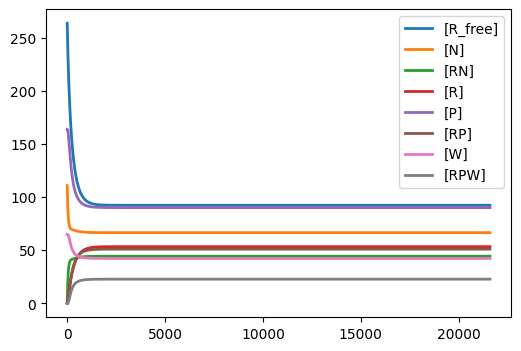

In [64]:
r_ext.plot()

In [65]:
dW_conditions_ext = {
       R_free_init: paras_dict_ext_local['N_R_ext'],
       RN_init: 0,
       R_init: 0,
       RP_init: 0, 
       RPW_init: 0, 
    
       N_init: config['base_parameters']['N_N'],
       W_init: config['base_parameters']['N_W']*0.05,
       P_init: config['base_parameters']['N_P'],
    }

In [66]:
# Update combined dictionary
paras_dict_local_dW = paras_dict_ext_local | dW_conditions_ext
paras_dict_ext_local_dW = {str(key): value for key, value in paras_dict_local_dW.items()}
    
# Simulate model for 6h since S8h 
Model_ext_dW = build_model(model_ext, paras_dict_ext_local_dW)
r_ext_dW = te.loada(Model_ext_dW)
Model_ext_dW = r_ext_dW.simulate(0, 3600*6, 3600*6)
    
columns = ['time', 'R_free', 'N', 'RN', 'R', 'P', 'RP', 'W', 'RPW']
    
df_dW = pd.DataFrame(Model_ext_dW, columns=columns)

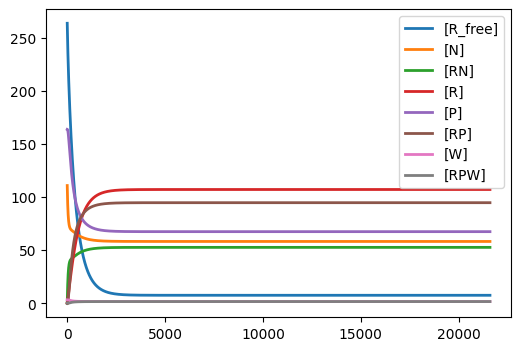

In [67]:
r_ext_dW.plot()

In [68]:
analysis_hours = 6
index = 3600 * analysis_hours - 1

# Calculate transition rates
rates = {
        'R_free_to_RN': paras_dict_ext_local_dW['Kext_R_free_RN'] * df_dW['N'][index],
        'RPW_R_free': paras_dict_ext_local_dW['Kext_RPW_R_free'],
        'RN_R': paras_dict_ext_local_dW['Kext_RN_R'],
        'R_RN': paras_dict_ext_local_dW['Kext_R_RN'] * df_dW['N'][index],
        'R_RP': paras_dict_ext_local_dW['Kext_R_RP'] * df_dW['P'][index],
        'RP_R': paras_dict_ext_local_dW['Kext_RP_R'],
        'RP_RPW': paras_dict_ext_local_dW['Kext_RP_RPW'] * df_dW['W'][index],
        'RPW_RP': paras_dict_ext_local_dW['Kext_RPW_RP'],
    }


In [69]:
# Load base parameters and update
with open(f"extrusion_dict_RN_RB_RP_RW_HBD_dW.json", "r") as f:
    output_params = json.load(f)
    
output_params["LEF_on_rate"]["A"] = float(rates['R_free_to_RN'])
output_params["LEF_off_rate"]["A"] = float(rates['RPW_R_free'])
output_params["LEF_stalled_off_rate"]["A"] = float(rates['RPW_R_free'])
output_params["LEF_transition_rates"]["21"]["A"] = float(rates['R_RN'])
output_params["LEF_transition_rates"]["23"]["A"] = float(rates['R_RP'])
output_params["LEF_transition_rates"]["12"]["A"] = float(rates['RN_R'])
output_params["LEF_transition_rates"]["32"]["A"] = float(rates['RP_R'])
output_params["LEF_transition_rates"]["34"]["A"] = float(rates['RP_RPW'])
output_params["LEF_transition_rates"]["43"]["A"] = float(rates['RPW_RP'])

In [70]:
filepath = Path("extrusion_dict_RN_RB_RP_RW_HBD_dW.json")

In [72]:
with open(filepath, "w") as f:
    json.dump(output_params, f, indent=4)